In [1]:
# Szükséges csomagok telepítése
!pip install pandas numpy scikit-learn tensorflow -q

# JSON fájl kezeléséhez
import json

# Adatkezeléshez
import pandas as pd
import numpy as np

# Közel-duplikátum kereséshez
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Tokenizáláshoz és paddinghez
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# A data.json fájl megnyitása UTF-8 kódolással
# A JSON tartalmát a "data" változóba töltjük

with open("data.json", "r", encoding="utf-8") as f:
    data = json.load(f)

print("A JSON fájl sikeresen beolvasva.")

A JSON fájl sikeresen beolvasva.


In [3]:
# Üres lista
# Ide gyűjtjük majd az eredeti és egyszerűsített mondatpárokat

rows = []


# A JSON struktúra rekurzív bejárása
#
# obj  = az aktuálisan vizsgált objektum
# path = azt tárolja, milyen útvonalon jutottunk el ide a JSON-ban

def process_data(obj, path=[]):

    # Csak dictionary objektumokkal dolgozunk tovább
    if isinstance(obj, dict):

        # Ha az aktuális dictionary tartalmaz abstract és adaptations részt,
        # akkor egy cikkhez érkeztünk
        if "abstract" in obj and "adaptations" in obj:

            # A path utolsó eleme lesz a cikk azonosítója
            article_id = path[-1]

            # Cikk címe
            title = obj["Title"]

            # Eredeti orvosi mondatok
            abstract = obj["abstract"]

            # Egyszerűsített változatok
            adaptations = obj["adaptations"]

            # Végigmegyünk az összes adaptation változaton
            for adaptation_name, adaptation in adaptations.items():

                # Végigmegyünk az eredeti mondatokon
                for sentence_id, original_text in abstract.items():

                    # Csak akkor vesszük fel,
                    # ha ugyanahhoz a mondathoz van egyszerűsített változat
                    if sentence_id in adaptation:

                        rows.append({
                            "article_id": article_id,
                            "title": title,
                            "sentence_id": sentence_id,
                            "original": original_text,
                            "simplified": adaptation[sentence_id],
                            "adaptation": adaptation_name
                        })

        # Tovább haladunk a JSON belsejében
        for key, value in obj.items():
            process_data(value, path + [key])


# Feldolgozás elindítása
process_data(data)

# Lista átalakítása Pandas DataFrame-é
df = pd.DataFrame(rows)

print("Kinyert sorok száma:", len(df))

df.head()

Kinyert sorok száma: 9319


,article_id,title,sentence_id,original,simplified,adaptation
0,15902691,Muscle cramps,1,Muscle cramps are a common problem characteriz...,Muscle cramps are a common problem represented...,adaptation2
1,15902691,Muscle cramps,2,"These true cramps, which originate from periph...","These true cramps, coming from nerves outside ...",adaptation2
2,15902691,Muscle cramps,3,"Medical history, physical examination, and a l...","Medical history, physical check-up, and lab sc...",adaptation2
3,15902691,Muscle cramps,4,"Despite the ""benign"" nature of cramps, many pa...","Despite their harmless nature, cramps are unco...",adaptation2
4,15902691,Muscle cramps,5,Treatment options are guided both by experienc...,Experience and limited medical studies guide t...,adaptation2


In [4]:
# A modell számára csak az eredeti és az egyszerűsített szöveg kell

ml_df = df[
    ["original", "simplified"]
].copy()

ml_df.head()

,original,simplified
0,Muscle cramps are a common problem characteriz...,Muscle cramps are a common problem represented...
1,"These true cramps, which originate from periph...","These true cramps, coming from nerves outside ..."
2,"Medical history, physical examination, and a l...","Medical history, physical check-up, and lab sc..."
3,"Despite the ""benign"" nature of cramps, many pa...","Despite their harmless nature, cramps are unco..."
4,Treatment options are guided both by experienc...,Experience and limited medical studies guide t...


In [5]:
# NaN / hiányzó értékek ellenőrzése

print("Hiányzó értékek:")
print(ml_df.isnull().sum())


# Üres stringek ellenőrzése
# A strip() levágja a szóközöket a szöveg elejéről és végéről

print("\nÜres original szövegek:",
      (ml_df["original"].str.strip() == "").sum())

print("Üres simplified szövegek:",
      (ml_df["simplified"].str.strip() == "").sum())

Hiányzó értékek:
original      0
simplified    0
dtype: int64

Üres original szövegek: 0
Üres simplified szövegek: 234


In [6]:
# A szövegek elejéről és végéről levágjuk a whitespace-eket

ml_df["original"] = ml_df["original"].astype(str).str.strip()
ml_df["simplified"] = ml_df["simplified"].astype(str).str.strip()


# Megjegyezzük, hány sor volt eredetileg

sorok_elotte = len(ml_df)


# Azokat a sorokat tartjuk meg,
# ahol sem az original, sem a simplified nem üres

ml_df = ml_df[
    (ml_df["original"] != "") &
    (ml_df["simplified"] != "")
].reset_index(drop=True)


sorok_utana = len(ml_df)


print(f"Eredeti sorok száma: {sorok_elotte}")
print(f"Üres sorok törlése után: {sorok_utana}")
print(f"Eltávolított üres sorok: {sorok_elotte - sorok_utana}")

Eredeti sorok száma: 9319
Üres sorok törlése után: 9085
Eltávolított üres sorok: 234


In [7]:
# Teljesen azonos original + simplified sorok számának ellenőrzése

print(
    "Duplikált sorok száma:",
    ml_df.duplicated().sum()
)


# Teljesen azonos sorok törlése

ml_df = ml_df.drop_duplicates().reset_index(drop=True)


print(
    "Duplikációk törlése után:",
    ml_df.duplicated().sum()
)

print("Maradt sorok száma:", len(ml_df))

Duplikált sorok száma: 9
Duplikációk törlése után: 0
Maradt sorok száma: 9076


In [8]:
print("KÖZEL DUPLIKÁTUMOK AZ ORIGINAL OSZLOPBAN\n")


# Az original szövegeket listává alakítjuk

szovegek = ml_df["original"].tolist()


# TF-IDF vektorizálás
#
# lowercase=True:
# minden szöveget kisbetűsít
#
# stop_words="english":
# a nagyon gyakori angol szavakat kihagyja
# pl. the, a, is

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)


# Szövegek átalakítása numerikus TF-IDF vektorokká

tfidf_matrix = vectorizer.fit_transform(szovegek)


# Minden mondat hasonlóságát kiszámítjuk minden másik mondathoz

similarity_matrix = cosine_similarity(tfidf_matrix)


# Egy mondat saját magával mindig 1.0 hasonlóságú lenne,
# ezért a főátlót lenullázzuk

np.fill_diagonal(similarity_matrix, 0)


# Közel-duplikátum küszöb

kuszob = 0.85


kozel_dupl_parok = []


# Csak a mátrix felső háromszögét nézzük,
# hogy ugyanazt a párt ne számoljuk kétszer

i_index, j_index = np.where(
    np.triu(similarity_matrix, k=1) >= kuszob
)


for i, j in zip(i_index, j_index):

    kozel_dupl_parok.append(
        (
            i,
            j,
            similarity_matrix[i, j]
        )
    )


print(
    "Talált közel-duplikátum párok száma:",
    len(kozel_dupl_parok)
)

KÖZEL DUPLIKÁTUMOK AZ ORIGINAL OSZLOPBAN

Talált közel-duplikátum párok száma: 1655


In [9]:
# Megnézzük, hogy különböző küszöbértékeknél
# hány hasonló pár található

for kuszob in [0.85, 0.90, 0.95, 0.98, 0.99, 1.0]:

    darab = np.sum(
        np.triu(similarity_matrix, k=1) >= kuszob
    )

    print(f"{kuszob}: {darab} pár")

0.85: 1655 pár
0.9: 1644 pár
0.95: 1636 pár
0.98: 1635 pár
0.99: 1635 pár
1.0: 1593 pár


In [10]:
# A leginkább hasonló párok kerüljenek előre

kozel_dupl_parok.sort(
    key=lambda x: x[2],
    reverse=True
)


# Első 30 pár kiírása

for i, j, hasonlosag in kozel_dupl_parok[:5]:

    print(f"\n[{i}] {szovegek[i]}")
    print(f"[{j}] {szovegek[j]}")

    print(
        f"Hasonlóság: {hasonlosag:.3f}"
    )


[2621] This review summarizes FLCN functional studies which support a role for FLCN in diverse metabolic pathways and cellular processes that include modulation of the mTOR pathway, regulation of PGC1α and mitochondrial biogenesis, cell-cell adhesion and RhoA signaling, control of TFE3/TFEB transcriptional activity, amino acid-dependent activation of mTORC1 on lysosomes through Rag GTPases, and regulation of autophagy.
[2625] This review summarizes FLCN functional studies which support a role for FLCN in diverse metabolic pathways and cellular processes that include modulation of the mTOR pathway, regulation of PGC1α and mitochondrial biogenesis, cell-cell adhesion and RhoA signaling, control of TFE3/TFEB transcriptional activity, amino acid-dependent activation of mTORC1 on lysosomes through Rag GTPases, and regulation of autophagy.
Hasonlóság: 1.000

[3534] Many products consumed by people and used in traditional medicine have been shown to contain substances with anti-inflammatory,

In [11]:
# FIGYELEM:
# Ha két original mondat hasonlósága legalább 0.85,
# a második sort törlésre jelöljük.

kuszob = 0.85

torlendo_indexek = set()


for i in range(len(ml_df)):

    for j in range(i + 1, len(ml_df)):

        if similarity_matrix[i, j] >= kuszob:

            # Mindig a későbbi sort jelöljük törlésre
            torlendo_indexek.add(j)


print(
    "Törlendő sorok száma:",
    len(torlendo_indexek)
)

Törlendő sorok száma: 1644


In [12]:
# A korábban kijelölt közel-duplikált sorok törlése

ml_df = ml_df.drop(
    index=list(torlendo_indexek)
).reset_index(drop=True)


print(
    "Maradt sorok száma:",
    len(ml_df)
)

Maradt sorok száma: 7432


In [13]:
# Tokenizer létrehozása az original szövegekhez
#
# Az <OOV> jelentése:
# Out Of Vocabulary
#
# Ha később olyan szó érkezik,
# amelyet a tokenizer nem ismer,
# ezt a speciális tokent használja.

tokenizer = Tokenizer(
    oov_token="<OOV>"
)


# A tokenizer megtanulja az original szövegek szókészletét

tokenizer.fit_on_texts(
    ml_df["original"]
)


# Szövegek átalakítása token ID sorozatokká

original_sequences = tokenizer.texts_to_sequences(
    ml_df["original"]
)


print(
    "Original szókészlet mérete:",
    len(tokenizer.word_index)
)

Original szókészlet mérete: 12629


In [14]:
# Az original token-sorozatokat azonos hosszúságúra egészítjük ki
#
# padding="post":
# a nullák a mondat végére kerülnek

original_padded = pad_sequences(
    original_sequences,
    padding="post"
)


print(
    "Original padded shape:",
    original_padded.shape
)

Original padded shape: (7432, 135)


In [15]:
# Külön tokenizert készítünk a simplified szövegekhez

target_tokenizer = Tokenizer(
    oov_token="<OOV>"
)


# A simplified szövegek szókészletének megtanulása

target_tokenizer.fit_on_texts(
    ml_df["simplified"]
)


# Simplified szövegek token ID-kké alakítása

simplified_sequences = target_tokenizer.texts_to_sequences(
    ml_df["simplified"]
)


# Padding

simplified_padded = pad_sequences(
    simplified_sequences,
    padding="post"
)


print(
    "Simplified szókészlet mérete:",
    len(target_tokenizer.word_index)
)

print(
    "Simplified padded shape:",
    simplified_padded.shape
)

Simplified szókészlet mérete: 9436
Simplified padded shape: (7432, 133)


In [16]:
# Egy konkrét példa megjelenítése

print("EREDETI SZÖVEG:")
print(
    ml_df.iloc[0]["original"]
)


print("\nTOKENIZÁLT:")
print(
    original_sequences[0]
)


print("\nPADDING UTÁN:")
print(
    original_padded[0]
)

EREDETI SZÖVEG:
Muscle cramps are a common problem characterized by a sudden, painful, involuntary contraction of muscle.

TOKENIZÁLT:
[410, 1284, 20, 7, 109, 1285, 440, 18, 7, 3203, 1139, 2114, 1870, 3, 410]

PADDING UTÁN:
[ 410 1284   20    7  109 1285  440   18    7 3203 1139 2114 1870    3
  410    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0]


In [17]:
# Ugyanannak a mintának az egyszerűsített változata

print("SIMPLIFIED SZÖVEG:")
print(
    ml_df.iloc[0]["simplified"]
)


print("\nTOKENIZÁLT:")
print(
    simplified_sequences[0]
)


print("\nPADDING UTÁN:")
print(
    simplified_padded[0]
)

SIMPLIFIED SZÖVEG:
Muscle cramps are a common problem represented by sudden, painful, involuntary muscle contractions.

TOKENIZÁLT:
[287, 921, 14, 7, 85, 754, 4867, 18, 1056, 1363, 2940, 287, 2941]

PADDING UTÁN:
[ 287  921   14    7   85  754 4867   18 1056 1363 2940  287 2941    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0]


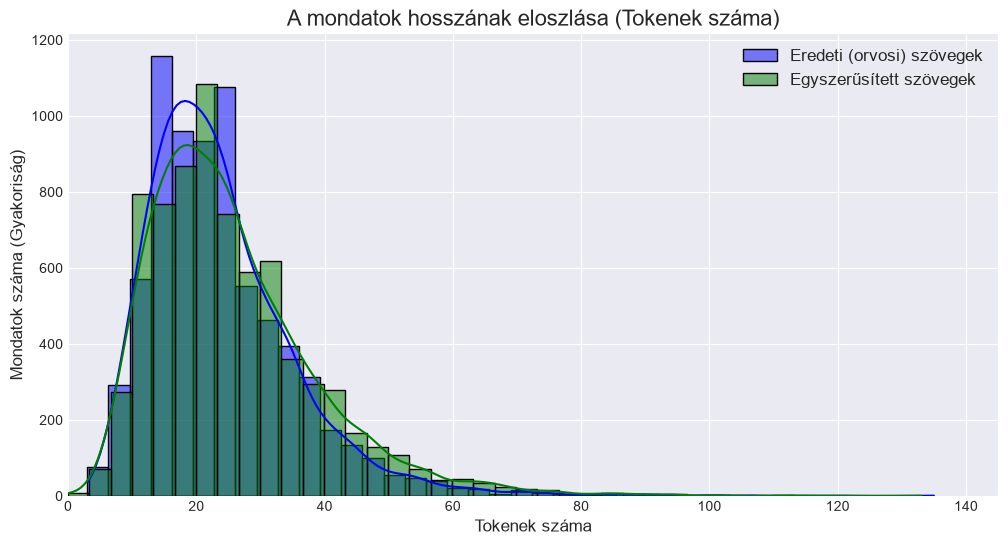

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Kiszámoljuk a tokenek számát (hosszát) minden egyes mondatnál
original_lengths = [len(seq) for seq in original_sequences]
simplified_lengths = [len(seq) for seq in simplified_sequences]

# 2. Rajzvászon és stílus beállítása
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(12, 6))

# 3. Hisztogramok kirajzolása
# A kde=True egy simított görbét is húz az oszlopok fölé
sns.histplot(original_lengths, bins=40, color='blue', alpha=0.5, label='Eredeti (orvosi) szövegek', kde=True)
sns.histplot(simplified_lengths, bins=40, color='green', alpha=0.5, label='Egyszerűsített szövegek', kde=True)

# 4. Feliratok és tengelyek
plt.title('A mondatok hosszának eloszlása (Tokenek száma)', fontsize=16)
plt.xlabel('Tokenek száma', fontsize=12)
plt.ylabel('Mondatok száma (Gyakoriság)', fontsize=12)
plt.xlim(0, max(max(original_lengths), max(simplified_lengths)) + 10)
plt.legend(fontsize=12)

# Ábra megjelenítése
plt.show()

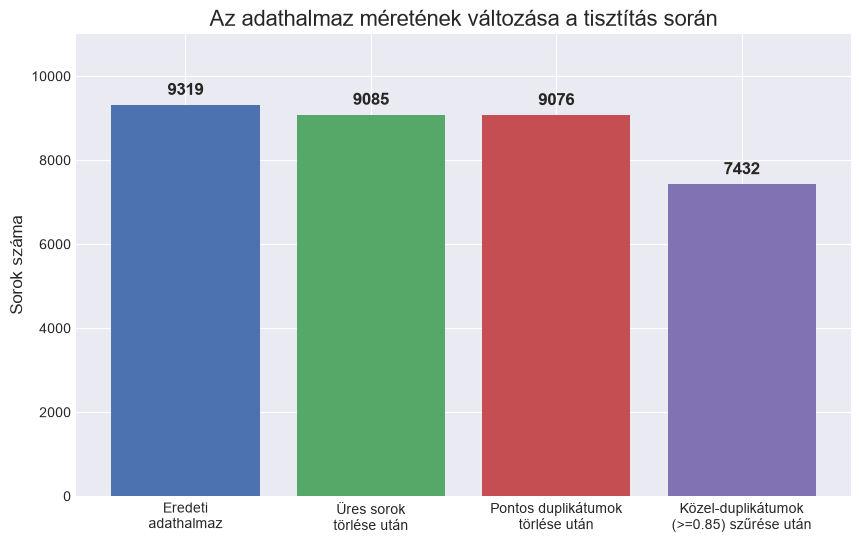

In [19]:
# 1. Az adatok megadása a korábbi lépéseid (print kimenetek) alapján
statisztika_nevek = [
    'Eredeti\nadathalmaz', 
    'Üres sorok\ntörlése után', 
    'Pontos duplikátumok\ntörlése után', 
    'Közel-duplikátumok\n(>=0.85) szűrése után'
]
sorok_szama = [9319, 9085, 9076, 7432]

# 2. Rajzvászon beállítása
plt.figure(figsize=(10, 6))
szinek = ['#4C72B0', '#55A868', '#C44E52', '#8172B3']

# 3. Oszlopdiagram elkészítése
bars = plt.bar(statisztika_nevek, sorok_szama, color=szinek)

# 4. A pontos számok ráírása az oszlopok tetejére
for bar in bars:
    yval = bar.get_height()
    # A szöveg elhelyezése picit az oszlop teteje fölött (yval + 150)
    plt.text(bar.get_x() + bar.get_width()/2, yval + 150, int(yval), 
             ha='center', va='bottom', fontsize=12, fontweight='bold')

# 5. Feliratok formázása
plt.title('Az adathalmaz méretének változása a tisztítás során', fontsize=16)
plt.ylabel('Sorok száma', fontsize=12)
plt.ylim(0, 11000) # Hogy legyen elég hely a feliratoknak az oszlopok felett

# Ábra megjelenítése
plt.show()

In [22]:
df.head(10)


,article_id,title,sentence_id,original,simplified,adaptation
0,15902691,Muscle cramps,1,Muscle cramps are a common problem characteriz...,Muscle cramps are a common problem represented...,adaptation2
1,15902691,Muscle cramps,2,"These true cramps, which originate from periph...","These true cramps, coming from nerves outside ...",adaptation2
2,15902691,Muscle cramps,3,"Medical history, physical examination, and a l...","Medical history, physical check-up, and lab sc...",adaptation2
3,15902691,Muscle cramps,4,"Despite the ""benign"" nature of cramps, many pa...","Despite their harmless nature, cramps are unco...",adaptation2
4,15902691,Muscle cramps,5,Treatment options are guided both by experienc...,Experience and limited medical studies guide t...,adaptation2
5,15902691,Muscle cramps,6,"Quinine sulfate is an effective medication, bu...","Quinine sulfate (an antimalarial drug) helps, ...",adaptation2
6,15902691,Muscle cramps,7,Patients will benefit from further studies to ...,More studies are needed to better define the e...,adaptation2
7,25432724,Diagnosis and treatment of dystonia,1,The dystonias are a group of disorders charact...,Dystonias are disorders with a lot of uncontro...,adaptation2
8,25432724,Diagnosis and treatment of dystonia,2,A careful assessment of the clinical manifesta...,Checking the symptoms can help identify patter...,adaptation2
9,25432724,Diagnosis and treatment of dystonia,3,"If a cause is identified, specific etiology-ba...","If a cause is found, specific cause-based trea...",adaptation2
